picking relevant evaluations

1. dumb classifiers
* predict largest
* proportionally random
* uniformly random

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score)

ROOT = Path("../data/bdneuro")
CLASSES = sorted(p.name for p in (ROOT / "train").iterdir() if p.is_dir())
SEED = 1738

def labels(split):
    """Class label for every image in a split, read from the folder structure."""
    return np.array([cls for cls in CLASSES for _ in (ROOT / split / cls).iterdir()])

y_train, y_val = labels("train"), labels("val")

# dummy classifiers ignore the input, so X is just a placeholder column
dummies = {
    "predict largest": DummyClassifier(strategy="most_frequent"),
    "proportionally random": DummyClassifier(strategy="stratified", random_state=SEED),
    "uniformly random": DummyClassifier(strategy="uniform", random_state=SEED),
}

overall, per_class = {}, {}
for name, clf in dummies.items():
    clf.fit(np.zeros((len(y_train), 1)), y_train)  # learns class frequencies from train only
    y_pred = clf.predict(np.zeros((len(y_val), 1)))
    overall[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "balanced acc": balanced_accuracy_score(y_val, y_pred),
        "macro F1": f1_score(y_val, y_pred, average="macro", zero_division=0),
        "weighted F1": f1_score(y_val, y_pred, average="weighted", zero_division=0),
    }
    per_class[name] = pd.DataFrame({
        "recall": recall_score(y_val, y_pred, labels=CLASSES, average=None, zero_division=0),
        "precision": precision_score(y_val, y_pred, labels=CLASSES, average=None, zero_division=0),
    }, index=CLASSES)

print("Overall metrics on val:")
display(pd.DataFrame(overall).T.round(3))
print("Per-class recall / precision on val:")
display(pd.concat(per_class, axis=1).round(3))

Overall metrics on val:


,accuracy,balanced acc,macro F1,weighted F1
predict largest,0.369,0.250,0.135,0.199
proportionally random,0.260,0.243,0.242,0.262
uniformly random,0.247,0.244,0.238,0.253


Per-class recall / precision on val:


predict largest           proportionally random            \
                    recall precision                recall precision   
glioma                 1.0     0.369                 0.319     0.348   
meningioma             0.0     0.000                 0.207     0.222   
no_tumor               0.0     0.000                 0.178     0.156   
pituitary              0.0     0.000                 0.269     0.242   

           uniformly random            
                     recall precision  
glioma                0.252     0.343  
meningioma            0.252     0.243  
no_tumor              0.229     0.128  
pituitary             0.242     0.258

Going with either balanced accuracy or macro-F1, any model will have to beat about 0.25 for both.

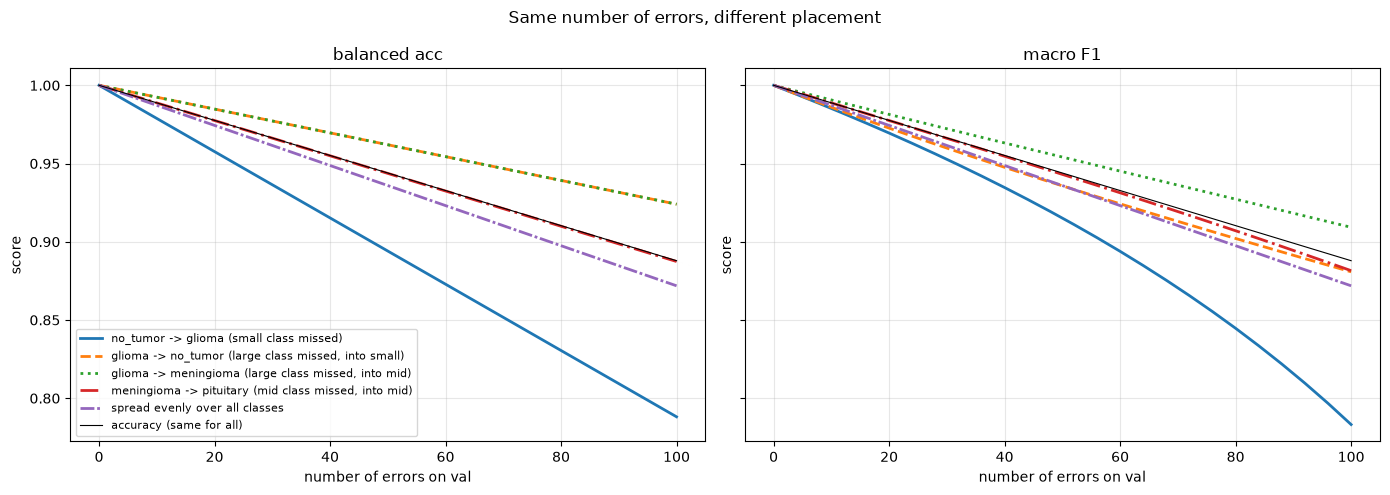

In [4]:
# Test D: the same number of errors, placed in a small vs a large class.
# Start from perfect predictions (a copy of the val labels) and corrupt n of them per scenario.
# For a given n, accuracy is identical in every scenario, so any difference between lines
# comes from how the metric weighs classes. Sweep n instead of picking one value.
import matplotlib.pyplot as plt

def corrupt(errors):
    """errors: list of (true_class, predicted_class, count). Returns corrupted predictions."""
    y_pred = y_val.copy()
    for true_cls, wrong_cls, n in errors:
        idx = np.where((y_val == true_cls) & (y_pred == true_cls))[0][:n]
        y_pred[idx] = wrong_cls
    return y_pred

def scenarios(n):
    return {
        "no_tumor -> glioma (small class missed)": [("no_tumor", "glioma", n)],
        "glioma -> no_tumor (large class missed, into small)": [("glioma", "no_tumor", n)],
        "glioma -> meningioma (large class missed, into mid)": [("glioma", "meningioma", n)],
        "meningioma -> pituitary (mid class missed, into mid)": [("meningioma", "pituitary", n)],
        "spread evenly over all classes": [(c, CLASSES[(i + 1) % len(CLASSES)], n // len(CLASSES))
                                           for i, c in enumerate(CLASSES)],
    }

ns = np.arange(0, 101, 4)  # multiples of 4 so the "spread" scenario has exactly n errors too
metrics = {"balanced acc": balanced_accuracy_score,
           "macro F1": lambda t, p: f1_score(t, p, average="macro")}
results = {m: {s: [] for s in scenarios(0)} for m in metrics}
for n in ns:
    for s, errors in scenarios(n).items():
        y_pred = corrupt(errors)
        for m, fn in metrics.items():
            results[m][s].append(fn(y_val, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, m in zip(axes, metrics):
    # different line styles, because some scenarios score identically and overlap exactly
    for (s, vals), ls in zip(results[m].items(), ["-", "--", ":", "-.", (0, (5, 1, 1, 1))]):
        ax.plot(ns, vals, label=s, ls=ls, lw=2)
    ax.plot(ns, 1 - ns / len(y_val), "k", lw=0.8, label="accuracy (same for all)")
    ax.set(title=m, xlabel="number of errors on val", ylabel="score")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Same number of errors, different placement")
plt.tight_layout(); plt.show()

* Balanced accuracy seems to be the better choice here, although monitoring both doesn't hurt.
* Mainly, mislabelling a small class as a larger class is not punishing enough in macro-F1. 